In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, shutil
import pandas as pd
import kagglehub

PROJECT_DIR = "/content/drive/MyDrive/spam_classifier_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
DATA_PATH  = f"{PROJECT_DIR}/emails.csv"
CLEAN_PATH = f"{PROJECT_DIR}/emails_clean.csv"
MODEL_PATH = f"{PROJECT_DIR}/spam_model.joblib"
VEC_PATH   = f"{PROJECT_DIR}/tfidf_vectorizer.joblib"

if not os.path.exists(DATA_PATH):
    src = kagglehub.dataset_download("purusinghvi/email-spam-classification-dataset")
    shutil.copy(glob.glob(f"{src}/*.csv")[0], DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df['label'].value_counts(normalize=True).round(3))

Mounted at /content/drive
(83448, 2)
label
1    0.526
0    0.474
Name: proportion, dtype: float64


In [ ]:
n0 = len(df)
data = df[['label', 'text']].copy()
data['text'] = data['text'].astype(str).str.strip()

# remove empty and very short emails (under 3 words)
data = data[data['text'].str.split().str.len() >= 3]

# remove texts that appear with both labels (contradictory)
conflict = data.groupby('text')['label'].nunique()
data = data[~data['text'].isin(conflict[conflict > 1].index)]

# remove duplicate texts
data = data.drop_duplicates(subset='text')

# cap extreme outliers at 2000 words
data['text'] = data['text'].apply(lambda t: " ".join(t.split()[:2000]))

data = data.reset_index(drop=True)
data.to_csv(CLEAN_PATH, index=False)

print(f"Rows: {n0:,} -> {len(data):,}")
print(data['label'].value_counts(normalize=True).round(3))

Rows: 83,448 -> 83,244
label
1    0.525
0    0.475
Name: proportion, dtype: float64


In [ ]:
import re, nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords', quiet=True)
stop = set(stopwords.words('english'))
leak = {'enron', 'ect', 'hou', 'vince', 'hpl', 'kaminski', 'escapenumber'}
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)   # URLs
    text = re.sub(r'[^a-z\s]', ' ', text)         # numbers and punctuation
    words = [w for w in text.split()
             if len(w) > 2 and w not in stop and w not in leak]
    return " ".join(stemmer.stem(w) for w in words)

CLEAN_TEXT_PATH = f"{PROJECT_DIR}/emails_processed.csv"

if os.path.exists(CLEAN_TEXT_PATH):
    data = pd.read_csv(CLEAN_TEXT_PATH).fillna("")
else:
    data['clean_text'] = data['text'].apply(preprocess)
    data = data[data['clean_text'].str.strip() != ""].reset_index(drop=True)
    data.to_csv(CLEAN_TEXT_PATH, index=False)

print(data.shape)
print(data['text'].iloc[0][:200])
print(data['clean_text'].iloc[0][:200])

(83176, 3)
ounce feather bowl hummingbird opec moment alabaster valkyrie dyad bread flack desperate iambic hadron heft quell yoghurt bunkmate divert afterimage
ounc feather bowl hummingbird opec moment alabast valkyri dyad bread flack desper iambic hadron heft quell yoghurt bunkmat divert afterimag


In [ ]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    data['clean_text'], data['label'],
    test_size=0.2, stratify=data['label'], random_state=42
)

if os.path.exists(VEC_PATH):
    vectorizer = joblib.load(VEC_PATH)
else:
    vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2),
                                 min_df=5, sublinear_tf=True)
    vectorizer.fit(X_train_txt)
    joblib.dump(vectorizer, VEC_PATH)

X_train = vectorizer.transform(X_train_txt)
X_test  = vectorizer.transform(X_test_txt)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train spam share:", round(y_train.mean(), 3), "| Test spam share:", round(y_test.mean(), 3))

Train: (66540, 50000) | Test: (16636, 50000)
Train spam share: 0.525 | Test spam share: 0.525


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

NB_PATH = f"{PROJECT_DIR}/model_nb.joblib"
LR_PATH = f"{PROJECT_DIR}/model_lr.joblib"

if os.path.exists(NB_PATH) and os.path.exists(LR_PATH):
    nb = joblib.load(NB_PATH)
    lr = joblib.load(LR_PATH)
    print("Loaded saved models.")
else:
    nb = MultinomialNB().fit(X_train, y_train)
    lr = LogisticRegression(max_iter=1000, C=10, random_state=42).fit(X_train, y_train)
    joblib.dump(nb, NB_PATH)
    joblib.dump(lr, LR_PATH)
    print("Trained and saved both models.")

Trained and saved both models.


                     Accuracy  Precision  Recall      F1
Naive Bayes            0.9751     0.9870  0.9652  0.9760
Logistic Regression    0.9878     0.9859  0.9910  0.9884

Best model: Logistic Regression

              precision    recall  f1-score   support

         Ham     0.9899    0.9843    0.9871      7901
        Spam     0.9859    0.9910    0.9884      8735

    accuracy                         0.9878     16636
   macro avg     0.9879    0.9876    0.9878     16636
weighted avg     0.9878    0.9878    0.9878     16636



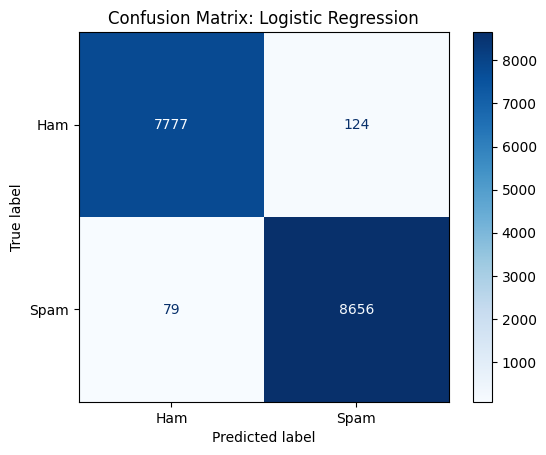


Top spam words: ['qualiti', 'attach http', 'life', 'remov', 'http', 'medic', 'info', 'men', 'pill', 'med', 'money', 'target', 'offer', 'site', 'softwar', 'comput', 'onlin', 'product', 'viagra', 'girl']
Top ham words:  ['wrote', 'thank', 'louis', 'perl', 'samba', 'doc', 'houston', 'debian', 'subject', 'employe', 'ga', 'attach', 'question', 'energi', 'forward', 'schedul', 'daren', 'xl', 'listinfo', 'mailman listinfo']


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

results = {}
for name, m in [("Naive Bayes", nb), ("Logistic Regression", lr)]:
    pred = m.predict(X_test)
    results[name] = {
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
    }
print(pd.DataFrame(results).T.round(4))

best = lr if results["Logistic Regression"]["F1"] >= results["Naive Bayes"]["F1"] else nb
best_name = "Logistic Regression" if best is lr else "Naive Bayes"
pred = best.predict(X_test)

print(f"\nBest model: {best_name}\n")
print(classification_report(y_test, pred, target_names=["Ham", "Spam"], digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Ham", "Spam"], cmap="Blues")
plt.title(f"Confusion Matrix: {best_name}")
plt.show()

# leakage check: strongest words for each class (Logistic Regression)
feats = np.array(vectorizer.get_feature_names_out())
coef = lr.coef_[0]
print("\nTop spam words:", list(feats[np.argsort(coef)[-20:][::-1]]))
print("Top ham words: ", list(feats[np.argsort(coef)[:20]]))


In [ ]:
joblib.dump(lr, MODEL_PATH)          # best model -> spam_model.joblib

model = joblib.load(MODEL_PATH)
vec   = joblib.load(VEC_PATH)

def predict_email(text):
    x = vec.transform([preprocess(text)])
    prob = model.predict_proba(x)[0, 1]
    return ("SPAM" if prob >= 0.5 else "NOT SPAM"), round(float(prob), 3)

tests = [
    "Congratulations! You won a $1000 gift card. Click here to claim your prize now!!!",
    "Hi team, please find attached the meeting notes from yesterday. Let's sync on Monday.",
    "Cheap meds online, no prescription needed, limited time offer, buy now",
]
for t in tests:
    print(predict_email(t), "<-", t[:60])

('SPAM', 0.858) <- Congratulations! You won a $1000 gift card. Click here to cl
('NOT SPAM', 0.003) <- Hi team, please find attached the meeting notes from yesterd
('SPAM', 1.0) <- Cheap meds online, no prescription needed, limited time offe


In [ ]:
feats = np.array(vec.get_feature_names_out())
coef = model.coef_[0]
print("Top spam words:", list(feats[np.argsort(coef)[-20:][::-1]]))
print("Top ham words: ", list(feats[np.argsort(coef)[:20]]))

Top spam words: ['qualiti', 'attach http', 'life', 'remov', 'http', 'medic', 'info', 'men', 'pill', 'med', 'money', 'target', 'offer', 'site', 'softwar', 'comput', 'onlin', 'product', 'viagra', 'girl']
Top ham words:  ['wrote', 'thank', 'louis', 'perl', 'samba', 'doc', 'houston', 'debian', 'subject', 'employe', 'ga', 'attach', 'question', 'energi', 'forward', 'schedul', 'daren', 'xl', 'listinfo', 'mailman listinfo']


In [ ]:
email = """Subject: URGENT!!! You Have Been Selected - Claim Your $5,000 Cash Prize Now

Dear Lucky Winner,

CONGRATULATIONS! Your email address was randomly selected in our monthly online
lottery draw. You have won $5,000 CASH PRIZE!!!

To claim your money, you must act within 24 hours. This is a LIMITED TIME OFFER
and will expire soon. Click the link below and enter your bank account details
and credit card number so we can transfer your winnings immediately:

http://claim-your-prize-now.biz/winner

Also get 80% OFF cheap pills, no prescription needed! Buy now and save big.
Make money fast from home, earn $500 per day with no experience required!

Reply today. Do not miss this once in a lifetime offer!

Click here to unsubscribe.

Best regards,
Prize Claims Department"""

x = vec.transform([preprocess(email)])
prob = float(model.predict_proba(x)[0, 1])
print("SPAM" if prob >= 0.5 else "NOT SPAM", "| spam probability:", round(prob, 3))

SPAM | spam probability: 1.0


In [ ]:
email = """Subject: Project meeting notes and next steps

Hi Ahmed,

Thank you for joining the project meeting yesterday. I have attached the notes
for your reference. Please review them and let me know if I missed anything.

The main points we discussed were:
- The report draft needs to be finished by Thursday.
- Sara will send the updated schedule to the team.
- We will meet again on Monday at 10 am to review the progress.

Could you please send me the latest version of the data file before Wednesday?
If you have any questions, feel free to call me or reply to this email.

Thanks again for your help.

Best regards,
Usman"""

x = vec.transform([preprocess(email)])
prob = float(model.predict_proba(x)[0, 1])
print("SPAM" if prob >= 0.5 else "NOT SPAM", "| spam probability:", round(prob, 3))

NOT SPAM | spam probability: 0.0


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import re, json, html, os, time, inspect
import numpy as np
import pandas as pd
import joblib, nltk
import gradio as gr
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# ---------- load saved model ----------
PROJECT_DIR  = "/content/drive/MyDrive/spam_classifier_project"
MAILBOX_PATH = f"{PROJECT_DIR}/mailbox.json"
model = joblib.load(f"{PROJECT_DIR}/spam_model.joblib")
vec   = joblib.load(f"{PROJECT_DIR}/tfidf_vectorizer.joblib")
feats = np.array(vec.get_feature_names_out())
coef  = model.coef_[0]

nltk.download('stopwords', quiet=True)
stop = set(stopwords.words('english'))
leak = {'enron', 'ect', 'hou', 'vince', 'hpl', 'kaminski', 'escapenumber'}
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [w for w in text.split() if len(w) > 2 and w not in stop and w not in leak]
    return " ".join(stemmer.stem(w) for w in words)

def analyze(text):
    x = vec.transform([preprocess(text)]).tocsr()
    prob = float(model.predict_proba(x)[0, 1])
    names, contrib = feats[x.indices], x.data * coef[x.indices]
    order = np.argsort(contrib)
    spam_sig = [names[i] for i in order[::-1] if contrib[i] > 0][:12]
    ham_sig  = [names[i] for i in order if contrib[i] < 0][:12]
    return prob, spam_sig, ham_sig

# ---------- mailbox storage ----------
THRESH = {"v": 0.5}
MAIL = []
if os.path.exists(MAILBOX_PATH):
    try:
        MAIL = json.load(open(MAILBOX_PATH))
        for m in MAIL:
            if not m["manual"]:
                m["folder"] = "spam" if m["prob"] >= THRESH["v"] else "inbox"
    except Exception:
        MAIL = []

def save():
    json.dump(MAIL, open(MAILBOX_PATH, "w"))

def get(mid):
    return next((m for m in MAIL if m["id"] == mid), None)

def add_mail(sender, subject, body):
    prob, spam_sig, ham_sig = analyze(f"{subject} {body}")
    m = {"id": max([x["id"] for x in MAIL], default=0) + 1,
         "time": time.strftime("%d %b %H:%M"),
         "sender": sender.strip() or "unknown@unknown",
         "subject": subject.strip() or "(no subject)",
         "body": body.strip(), "prob": prob,
         "spam_sig": spam_sig, "ham_sig": ham_sig, "manual": False,
         "folder": "spam" if prob >= THRESH["v"] else "inbox"}
    MAIL.append(m); save()
    return m

# ---------- HTML renderers ----------
CSS = """
.hdr{padding:20px 24px;border-radius:14px;background:linear-gradient(135deg,#4f46e5,#7c3aed);color:#fff}
.hdr h1{margin:0;font-size:26px;color:#fff}
.hdr p{margin:6px 0 0;opacity:.9;font-size:14px}
.stats{display:grid;grid-template-columns:repeat(4,1fr);gap:12px;margin:6px 0}
.card{padding:14px;border-radius:12px;text-align:center;background:var(--background-fill-secondary);border:1px solid var(--border-color-primary)}
.card .num{font-size:28px;font-weight:700}
.card .lbl{font-size:12px;opacity:.7;text-transform:uppercase;letter-spacing:.06em}
.verdict,.reader{padding:18px;border-radius:12px;background:var(--background-fill-secondary);border:2px solid var(--border-color-primary)}
.vtitle{font-size:26px;font-weight:800;margin-bottom:2px}
.barlbl{display:flex;justify-content:space-between;margin-top:12px;font-size:14px}
.bar{height:12px;border-radius:8px;background:rgba(128,128,128,.25);overflow:hidden;margin-top:4px}
.fill{height:100%;border-radius:8px}
.sect{margin:14px 0 6px;font-size:12px;font-weight:700;text-transform:uppercase;letter-spacing:.06em;opacity:.7}
.chip{display:inline-block;padding:3px 10px;margin:2px 4px 2px 0;border-radius:999px;font-size:13px;font-weight:600}
.chip.red{background:rgba(220,38,38,.15);color:#dc2626}
.chip.green{background:rgba(22,163,74,.15);color:#16a34a}
.muted,.note{opacity:.7;font-size:13px}
.note{margin-top:12px}
.empty{padding:28px;text-align:center;opacity:.6;border:2px dashed var(--border-color-primary);border-radius:12px}
.rsub{font-size:20px;font-weight:700}
.rmeta{font-size:13px;opacity:.85;margin:6px 0 12px}
.badge{color:#fff;padding:2px 10px;border-radius:999px;font-size:12px;font-weight:700}
.rbody{line-height:1.6;padding:12px;border-radius:8px;background:rgba(128,128,128,.1);max-height:260px;overflow:auto}
mark.hl{background:rgba(220,38,38,.28);color:inherit;padding:0 3px;border-radius:4px}

/* hide footer: "Use via API", "Built with Gradio", "Settings" */
footer, .show-api, .built-with, .settings, button.settings {display:none !important}

/* modern navigation bar */
.tab-wrapper{position:sticky;top:0;z-index:50;padding:10px 0;background:var(--body-background-fill)}
.tab-wrapper, .tab-container{border:none !important}
.tab-container::after, button[role="tab"]::after{display:none !important}
button[role="tab"]{
  font-size:15px;font-weight:600;padding:10px 22px;margin-right:8px;
  border:none !important;border-radius:999px !important;
  background:var(--background-fill-secondary);transition:all .2s ease}
button[role="tab"]:hover{background:rgba(79,70,229,.14)}
button[role="tab"][aria-selected="true"]{
  background:linear-gradient(135deg,#4f46e5,#7c3aed) !important;
  color:#fff !important;box-shadow:0 4px 12px rgba(79,70,229,.35)}
"""

HEADER = """<div class="hdr"><h1>📧 Smart Spam Filter</h1>
<p>TF-IDF + Logistic Regression &middot; 98.8% accuracy on held-out test data &middot; emails are analyzed and filed automatically</p></div>"""

EMPTY_VERDICT = '<div class="empty">Receive an email to see the model\'s analysis here.</div>'
TCOLS = ["#", "Time", "From", "Subject", "Spam %", "Folder"]

def stats_html():
    n = len(MAIL); s = sum(m["folder"] == "spam" for m in MAIL)
    rate = f"{100 * s / n:.0f}%" if n else "0%"
    cards = [("Total", n, "#4f46e5"), ("Inbox", n - s, "#16a34a"),
             ("Spam", s, "#dc2626"), ("Spam rate", rate, "#d97706")]
    return '<div class="stats">' + "".join(
        f'<div class="card" style="border-top:4px solid {c}"><div class="num">{v}</div><div class="lbl">{l}</div></div>'
        for l, v, c in cards) + '</div>'

def chips(words, cls, n=8):
    return "".join(f'<span class="chip {cls}">{html.escape(w)}</span>' for w in words[:n]) \
        or '<span class="muted">none found</span>'

def highlight(body, spam_words):
    sw = set(spam_words)
    out = []
    for p in re.split(r'([A-Za-z]+)', body[:5000]):
        if p and p.isalpha() and stemmer.stem(p.lower()) in sw:
            out.append(f'<mark class="hl">{html.escape(p)}</mark>')
        else:
            out.append(html.escape(p))
    return "".join(out).replace("\n", "<br>")

def verdict_html(m):
    p = m["prob"]; spam = p >= THRESH["v"]
    col = "#dc2626" if spam else "#16a34a"
    title = "🚫 SPAM" if spam else "✅ NOT SPAM"
    where = "Spam folder" if m["folder"] == "spam" else "Inbox"
    return f"""
<div class="verdict" style="border-color:{col}">
  <div class="vtitle" style="color:{col}">{title}</div>
  <div class="muted">{html.escape(m['subject'])} &middot; filed to <b>{where}</b></div>
  <div class="barlbl"><span>Spam probability</span><b>{p*100:.1f}%</b></div>
  <div class="bar"><div class="fill" style="width:{p*100:.1f}%;background:{col}"></div></div>
  <div class="sect">Words pushing toward spam</div>{chips(m['spam_sig'], 'red')}
  <div class="sect">Words pushing toward legitimate</div>{chips(m['ham_sig'], 'green')}
  <div class="note">Words appear in stemmed form (e.g. "qualiti"), as the model sees them.</div>
</div>"""

def reader_html(m):
    if not m:
        return '<div class="empty">Select an email in the table to read it here.</div>'
    bc = "#dc2626" if m["folder"] == "spam" else "#16a34a"
    spam_words = [w for w in m["spam_sig"] if " " not in w]
    return f"""
<div class="reader">
  <div class="rsub">{html.escape(m['subject'])}</div>
  <div class="rmeta">From <b>{html.escape(m['sender'])}</b> &middot; {m['time']} &middot;
    <span class="badge" style="background:{bc}">{m['folder'].title()}</span> &middot;
    spam probability <b>{m['prob']*100:.1f}%</b></div>
  <div class="rbody">{highlight(m['body'], spam_words)}</div>
  <div class="sect">Spam signals found</div>{chips(m['spam_sig'], 'red', 10)}
</div>"""

def table(folder, q):
    rows = [m for m in MAIL if folder == "All" or m["folder"] == folder.lower()]
    if q and q.strip():
        ql = q.lower()
        rows = [m for m in rows if ql in (m["sender"] + m["subject"] + m["body"]).lower()]
    rows = sorted(rows, key=lambda m: -m["id"])
    return pd.DataFrame([[m["id"], m["time"], m["sender"], m["subject"],
                          f"{m['prob']*100:.1f}%", m["folder"].title()] for m in rows], columns=TCOLS)

def refresh(folder, q):
    return stats_html(), table(folder, q)

# ---------- sample emails ----------
SAMPLES = [
 ["winner@lucky-draw-prizes.biz", "URGENT!!! You won $10,000 cash prize",
  "Dear Lucky Winner, CONGRATULATIONS! You have won $10,000 CASH! Act within 24 hours, limited time offer. Click http://claim-prize-now.biz and enter your bank account and credit card details so we can transfer your winnings immediately."],
 ["orders@cheap-meds-online.net", "80% OFF pills, no prescription needed",
  "Buy viagra and other medication online. Best quality, lowest prices, discreet shipping. No prescription needed. Order now and save money, limited stock! Click here to remove yourself from this list."],
 ["director@union-bank-nigeria.com", "Confidential business proposal",
  "I know this proposal will come as a surprise since you do not know me. I have a huge sum of money, 25 million dollars, that needs a trustworthy foreign partner. Reply to my private email address with your full name and bank account details. This is strictly confidential."],
 ["usman@company.com", "Project meeting notes",
  "Hi Ahmed, thank you for joining the project meeting yesterday. I have attached the notes. Please review them and send me the latest data file before Wednesday. We will meet again on Monday at 10 am to review progress."],
 ["sara@university.edu", "Assignment deadline extended",
  "Dear students, the deadline for the final project report has been moved to Friday. Please submit it through the course portal. If you have any questions, reply to this email or visit my office hours on Thursday."],
 ["hr@company.com", "Team schedule for next week",
  "Hello team, please find the updated schedule for next week. The planning meeting is on Tuesday at 2 pm and the client presentation is on Thursday. Kindly confirm your availability by tomorrow evening."],
]

# ---------- event handlers ----------
def do_receive(s, sub, b, folder, q):
    if not (sub.strip() or b.strip()):
        gr.Warning("Enter a subject or message first.")
        return (EMPTY_VERDICT, *refresh(folder, q), s, sub, b)
    m = add_mail(s, sub, b)
    return (verdict_html(m), *refresh(folder, q), "", "", "")

def do_samples(folder, q):
    existing = {(m["sender"], m["subject"]) for m in MAIL}
    added = 0
    for s, sub, b in SAMPLES:
        if (s, sub) not in existing:
            add_mail(s, sub, b); added += 1
    gr.Info(f"Loaded {added} sample emails.")
    return refresh(folder, q)

def on_filter(folder, q):
    return table(folder, q), reader_html(None), None

def on_select(folder, q, evt: gr.SelectData):
    rv = getattr(evt, "row_value", None)
    if rv:
        mid = int(rv[0])
    else:
        df = table(folder, q)
        r = evt.index[0] if isinstance(evt.index, (list, tuple)) else evt.index
        if r >= len(df):
            return None, reader_html(None)
        mid = int(df.iloc[r]["#"])
    return mid, reader_html(get(mid))

def do_move(mid, folder, q):
    m = get(mid)
    if not m:
        gr.Warning("Select an email in the table first.")
        return (mid, *refresh(folder, q), reader_html(None))
    m["folder"] = "inbox" if m["folder"] == "spam" else "spam"
    m["manual"] = True; save()
    gr.Info(f"Moved to {m['folder'].title()}.")
    return (None, *refresh(folder, q), reader_html(None))

def do_delete(mid, folder, q):
    m = get(mid)
    if not m:
        gr.Warning("Select an email in the table first.")
        return (mid, *refresh(folder, q), reader_html(None))
    MAIL.remove(m); save()
    return (None, *refresh(folder, q), reader_html(None))

def do_clear(folder, q):
    MAIL.clear(); save()
    return (None, *refresh(folder, q), reader_html(None), EMPTY_VERDICT)

def set_threshold(v, folder, q):
    THRESH["v"] = v
    for m in MAIL:
        if not m["manual"]:
            m["folder"] = "spam" if m["prob"] >= v else "inbox"
    save()
    return refresh(folder, q)

# ---------- UI ----------
gr.close_all()
THEME = gr.themes.Soft(primary_hue="indigo")
G6 = "css" in inspect.signature(gr.Blocks.launch).parameters   # True on Gradio 6

with gr.Blocks(title="Smart Spam Filter", **({} if G6 else dict(theme=THEME, css=CSS))) as demo:
    gr.HTML(HEADER)
    stats = gr.HTML(stats_html())
    sel = gr.State(None)

    with gr.Tabs():
        with gr.Tab("📨 Receive Email"):
            with gr.Row():
                with gr.Column(scale=1):
                    sender  = gr.Textbox(label="From", placeholder="sender@example.com")
                    subject = gr.Textbox(label="Subject")
                    body    = gr.Textbox(label="Message", lines=9)
                    with gr.Row():
                        send_btn    = gr.Button("📨 Receive & Filter", variant="primary")
                        samples_btn = gr.Button("Load sample emails")
                    gr.Examples(examples=SAMPLES, inputs=[sender, subject, body],
                                label="Click an example to fill the form")
                with gr.Column(scale=1):
                    verdict = gr.HTML(EMPTY_VERDICT)

        with gr.Tab("📂 Mailbox"):
            with gr.Row():
                folder = gr.Radio(["Inbox", "Spam", "All"], value="Inbox", label="Folder", scale=2)
                search = gr.Textbox(label="Search", placeholder="sender, subject or text...", scale=3)
            table_out = gr.Dataframe(value=table("Inbox", ""), interactive=False, wrap=True)
            reader = gr.HTML(reader_html(None))
            with gr.Row():
                move_btn  = gr.Button("🔁 Move to other folder")
                del_btn   = gr.Button("🗑️ Delete", variant="stop")
                clear_btn = gr.Button("Clear mailbox")

        with gr.Tab("⚙️ Settings"):
            thr = gr.Slider(0.1, 0.9, value=0.5, step=0.05, label="Spam threshold",
                            info="Lower = stricter filter (more emails marked spam). Higher = more lenient.")
            gr.Markdown("Changing the threshold re-files all emails you have not moved by hand. "
                        "Your mailbox is saved to `mailbox.json` in your Google Drive project folder.")

    # wiring
    send_btn.click(do_receive, [sender, subject, body, folder, search],
                   [verdict, stats, table_out, sender, subject, body])
    samples_btn.click(do_samples, [folder, search], [stats, table_out])
    folder.change(on_filter, [folder, search], [table_out, reader, sel])
    search.change(on_filter, [folder, search], [table_out, reader, sel])
    table_out.select(on_select, [folder, search], [sel, reader])
    move_btn.click(do_move, [sel, folder, search], [sel, stats, table_out, reader])
    del_btn.click(do_delete, [sel, folder, search], [sel, stats, table_out, reader])
    clear_btn.click(do_clear, [folder, search], [sel, stats, table_out, reader, verdict])
    thr.release(set_threshold, [thr, folder, search], [stats, table_out])

launch_kw = dict(share=True)
params = inspect.signature(demo.launch).parameters
if G6:
    launch_kw.update(theme=THEME, css=CSS)
if "show_api" in params:
    launch_kw["show_api"] = False
if "footer_links" in params:
    launch_kw["footer_links"] = []
demo.launch(**launch_kw)

Mounted at /content/drive
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1ee122744a64dc121f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
